# Question 2

We can also use the same formula to make weather predictions. View the table below showing weather observations across 8 days. If we observe no humidity, a cold temperature and slow wind, is the weather likely to be sunny or rainy?

![Table](./images/reference/week_3_lessons_2_q2.png)

In [1]:
from pydoc import describe

import pandas as pd
from IPython.display import display
from sklearn.preprocessing import OrdinalEncoder
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

def style_latex_table(styler):
    """Style LaTeX tables; requires colortbl in the PDF template."""
    def stripe_rows(values):
        return [
            # Wrap the content directly to avoid a leading space after cellcolor.
            "cellcolor:{gray!10}--rwrap;" if i % 2 == 0 else ""
            for i in range(len(values))
        ]

    def style_index(values):
        return [style + "bfseries:;" for style in stripe_rows(values)]

    return (
        styler
        .apply(stripe_rows, axis=0)
        .apply_index(style_index, axis=0)
        .map_index(lambda value: "bfseries:;", axis=1)
    )

# 1. Recreate the DataFrame
weather_df = pd.DataFrame([
    ("Humid", "Hot", "Fast", "Sunny"),
    ("Humid", "Hot", "Fast", "Sunny"),
    ("Humid", "Hot", "Slow", "Sunny"),
    ("Not Humid", "Cold", "Fast", "Sunny"),
    ("Not Humid", "Hot", "Slow", "Rainy"),
    ("Not Humid", "Cold", "Fast", "Rainy"),
    ("Humid", "Hot", "Slow", "Rainy"),
    ("Humid", "Cold", "Slow", "Rainy"),
], columns=["Humidity", "Temperature", "Wind Speed", "Weather"])

weather_df

,Humidity,Temperature,Wind Speed,Weather
0,Humid,Hot,Fast,Sunny
1,Humid,Hot,Fast,Sunny
2,Humid,Hot,Slow,Sunny
3,Not Humid,Cold,Fast,Sunny
4,Not Humid,Hot,Slow,Rainy
5,Not Humid,Cold,Fast,Rainy
6,Humid,Hot,Slow,Rainy
7,Humid,Cold,Slow,Rainy


Shape of the DataFrame:

In [2]:
print(f"The dataframe has {weather_df.shape[0]} rows and {weather_df.shape[1]} columns.")

The dataframe has 8 rows and 4 columns.


This can be grouped as:

In [3]:
for column in weather_df.columns:
    print(f"\n{column} (%)")
    percentages = weather_df[column].value_counts(normalize=True).mul(100)
    print(percentages.rename_axis(None).to_string())


Humidity (%)
Humid        62.5
Not Humid    37.5

Temperature (%)
Hot     62.5
Cold    37.5

Wind Speed (%)
Fast    50.0
Slow    50.0

Weather (%)
Sunny    50.0
Rainy    50.0


## Predicting Weather Using Naive Bayes

We want to predict **Weather** given three features:

- $H$: Humidity
- $T$: Temperature
- $V$: Wind Speed
- $W$: Weather (Sunny or Rainy)

We do **not** calculate $P(H \mid T)$, then $P(T \mid V)$, then $P(V \mid W)$. Instead, Bayes' theorem gives:

$$
P(W \mid H,T,V)
=
\frac{P(H,T,V \mid W)\,P(W)}{P(H,T,V)}
$$

### Naive Bayes assumption

Naive Bayes assumes that the features are **conditionally independent given the weather**:

$$
P(H,T,V \mid W)
=
P(H \mid W)\,P(T \mid W)\,P(V \mid W)
$$

Therefore:

$$
P(W \mid H,T,V)
\propto
P(H \mid W)\,P(T \mid W)\,P(V \mid W)\,P(W)
$$

We calculate a score for each weather category, then normalize the scores to obtain probabilities. Multiplication order does not matter.

### Example: Humid, Hot, Fast

From the dataframe:

| Probability | Sunny | Rainy |
|---|---:|---:|
| $P(W)$ | $4/8$ | $4/8$ |
| $P(H=\text{Humid} \mid W)$ | $3/4$ | $2/4$ |
| $P(T=\text{Hot} \mid W)$ | $3/4$ | $2/4$ |
| $P(V=\text{Fast} \mid W)$ | $3/4$ | $1/4$ |

The unnormalized scores are:

$$
s_{\text{Sunny}}
=
\frac{4}{8}
\times \frac{3}{4}
\times \frac{3}{4}
\times \frac{3}{4}
=
\frac{27}{128}
$$

$$
s_{\text{Rainy}}
=
\frac{4}{8}
\times \frac{2}{4}
\times \frac{2}{4}
\times \frac{1}{4}
=
\frac{4}{128}
$$

Normalize by dividing each score by the sum of both scores:

$$
P(\text{Sunny} \mid \text{Humid, Hot, Fast})
=
\frac{27/128}{27/128 + 4/128}
=
\frac{27}{31}
\approx 87.1\%
$$

$$
P(\text{Rainy} \mid \text{Humid, Hot, Fast})
=
\frac{4/128}{27/128 + 4/128}
=
\frac{4}{31}
\approx 12.9\%
$$

**Prediction: Sunny**, under the naive Bayes assumption, using the observed frequencies without smoothing.

### Without the independence assumption

The exact probability chain rule is:

$$
P(H,T,V \mid W)
=
P(H \mid W)\,
P(T \mid H,W)\,
P(V \mid H,T,W)
$$

Each factor retains the weather condition and includes the preceding features. Other feature orders are also valid when the conditioning is adjusted accordingly.

### Resolving question 2

I create a function to calculate the probabilities:

In [4]:
def obtain_probability_table(observation: dict[str, str]):
    weather_counts = weather_df["Weather"].value_counts()
    categories = ["Sunny", "Rainy"]

    fractions_str = {
        "P(W)": [
            f"{weather_counts[w]}/{len(weather_df)}"
            for w in categories
        ]
    }

    '''fractions_float = {
        "P(W)": [
            weather_counts[w] / len(weather_df)
            for w in categories
        ]
    }'''

    for feature, value in observation.items():
        # Count matching rows within each weather category
        matching_counts = (
            weather_df[feature].eq(value)
            .groupby(weather_df["Weather"])
            .sum()
        )

        fractions_str[f"P({feature}={value} | W)"] = [
            f"{matching_counts[w]}/{weather_counts[w]}"
            for w in categories
        ]

        '''fractions_float[f"P({feature}={value} | W)"] = [
            matching_counts[w] / weather_counts[w]
            for w in categories
        ]'''

    probability_table_str = pd.DataFrame(fractions_str, index=categories).T
    #probability_table_float = pd.DataFrame(fractions_float, index=categories).T

    return probability_table_str #, probability_table_float

def obtain_prediction(probability_table : pd.DataFrame, debug_mode=False):
    # I will convert the fractions to floats:
    probability_table_float = probability_table.map(
        lambda fraction: int(fraction.split("/")[0]) / int(fraction.split("/")[1])
    )
    if debug_mode:
        print("Probability table in float")
        display(probability_table_float)

    # I will multiply by column to get the sunny and rainy days:
    scores = probability_table_float.prod(axis=0)
    if debug_mode:
        print("Sunny and rainy days")
        display(scores.to_frame(name="Score"))

    # Then normalize the scores to get the predicted probabilities:
    posterior = scores / scores.sum()
    if debug_mode:
        print("\nSunny and rainy days normalised")
        posterior_table = posterior.to_frame(name="Probability")
        ''' Not nbconvert compatible.
        display(
            posterior.to_frame(name="Probability").style.format("{:.2%}")
        )'''
        display({
            "text/html": posterior_table.style.format("{:.2%}").to_html(),
            "text/latex": style_latex_table(posterior_table.style.format(
                lambda x: f"{x:.2%}".replace("%", r"\%")
            )).to_latex(),
        }, raw=True)

    prediction = posterior.idxmax()  # e..g "Sunny"
    if debug_mode:
        print("\nPrediction:", prediction)

    return prediction

# Feature values for the observation we want to predict
observation = {
    "Humidity": "Humid",
    "Temperature": "Hot",
    "Wind Speed": "Fast",
}

probability_table = obtain_probability_table(observation)

display(probability_table)

'''probability_table_float = probability_table.map(
    lambda fraction: int(fraction.split("/")[0]) / int(fraction.split("/")[1])
)

display(probability_table_float)'''

#probability_table.describe()

,Sunny,Rainy
P(W),4/8,4/8
P(Humidity=Humid | W),3/4,2/4
P(Temperature=Hot | W),3/4,2/4
P(Wind Speed=Fast | W),3/4,1/4


'probability_table_float = probability_table.map(\n    lambda fraction: int(fraction.split("/")[0]) / int(fraction.split("/")[1])\n)\n\ndisplay(probability_table_float)'

I will work out the prediction:

In [5]:
prediction = obtain_prediction(probability_table, debug_mode=True)

Probability table in float


,Sunny,Rainy
P(W),0.50,0.50
P(Humidity=Humid | W),0.75,0.50
P(Temperature=Hot | W),0.75,0.50
P(Wind Speed=Fast | W),0.75,0.25


Sunny and rainy days


,Score
Sunny,0.210938
Rainy,0.031250



Sunny and rainy days normalised


,Probability
Sunny,87.10%
Rainy,12.90%



Prediction: Sunny


Then I do the same for the observation we want to predict: If we observe no humidity, a cold temperature and slow wind, is the weather likely to be sunny or rainy?

In [6]:
observation = {
    "Humidity": "Not Humid",
    "Temperature": "Cold",
    "Wind Speed": "Slow",
}

probability_table = obtain_probability_table(observation)

display(probability_table)

obtain_prediction(probability_table, debug_mode=True)

,Sunny,Rainy
P(W),4/8,4/8
P(Humidity=Not Humid | W),1/4,2/4
P(Temperature=Cold | W),1/4,2/4
P(Wind Speed=Slow | W),1/4,3/4


Probability table in float


,Sunny,Rainy
P(W),0.50,0.50
P(Humidity=Not Humid | W),0.25,0.50
P(Temperature=Cold | W),0.25,0.50
P(Wind Speed=Slow | W),0.25,0.75


Sunny and rainy days


,Score
Sunny,0.007812
Rainy,0.093750



Sunny and rainy days normalised


,Probability
Sunny,7.69%
Rainy,92.31%



Prediction: Rainy


'Rainy'

## Discrepancy in the Worked Naive Bayes Solution

### IATD proposed (incorrect) solution

![Incorrect solution](./images/reference/Naive%20Bayes%20Weather%20Calculations.png)

### Why?

For the observation **Humidity = Not Humid, Temperature = Cold, Wind = Slow**, both calculations predict **Rainy**. However, the worked solution uses an incorrect probability decomposition.

Let:

- $W$: Weather
- $H$: Humidity
- $T$: Temperature
- $V$: Wind speed

### 1. Incorrect decomposition in the worked solution

The worked solution begins with:

$$
P(W \mid H,T,V)
=
P(W \mid H)\,P(W \mid T)\,P(W \mid V)
$$

This equality does not hold in general and does not follow from the naive Bayes assumption.

Naive Bayes assumes that the **features are conditionally independent given the weather**:

$$
P(H,T,V \mid W)
=
P(H \mid W)\,P(T \mid W)\,P(V \mid W)
$$

Consequently, the correct scoring formula is:

$$
s_W = P(W)\,P(H \mid W)\,P(T \mid W)\,P(V \mid W)
$$

The posterior probabilities are obtained by normalizing these scores across the weather categories.

### 2. Why the numerical values differ

Applying Bayes' theorem separately to each factor in the worked solution gives:

$$
P(W \mid H)\,P(W \mid T)\,P(W \mid V)
=
\frac{
P(H \mid W)\,P(T \mid W)\,P(V \mid W)\,P(W)^3
}{
P(H)\,P(T)\,P(V)
}
$$

This includes the prior $P(W)$ **three times**, whereas the correct naive Bayes score includes it **once**.

For this dataset, the worked solution therefore multiplies each correct score by:

$$
\frac{P(W)^2}{P(H)\,P(T)\,P(V)}
=
\frac{(4/8)^2}{(3/8)(3/8)(4/8)}
=
\frac{32}{9}
$$

### 3. Comparison of results

The correct unnormalized scores are:

$$
s_{\text{Sunny}}
=
\frac{4}{8}\times\frac{1}{4}\times\frac{1}{4}\times\frac{1}{4}
=
0.0078125
$$

$$
s_{\text{Rainy}}
=
\frac{4}{8}\times\frac{2}{4}\times\frac{2}{4}\times\frac{3}{4}
=
0.09375
$$

| Weather | Correct unnormalized score | Worked solution's value |
|---|---:|---:|
| Sunny | 0.0078125 | 0.0277778 |
| Rainy | 0.09375 | 0.3333333 |

Because the two weather categories have equal priors, the incorrect method multiplies both scores by the same constant. It therefore preserves their ratio of $1:12$.

Normalizing the correct scores gives:

$$
P(\text{Sunny} \mid H,T,V)
=
\frac{0.0078125}{0.0078125+0.09375}
=
\frac{1}{13}
\approx 7.69\%
$$

$$
P(\text{Rainy} \mid H,T,V)
=
\frac{0.09375}{0.0078125+0.09375}
=
\frac{12}{13}
\approx 92.31\%
$$

These are the posterior probabilities under the naive Bayes assumption. The worked solution's displayed values are not normalized posterior probabilities.

### Conclusion

Although both methods arrive at the same classification—**Rainy**—the way the worked solution obtains its result is not correct. It multiplies individual posterior probabilities and consequently includes the weather prior three times. The prediction agrees in this example because the class priors are equal; with unequal priors, this error can produce a different and incorrect classification.

### References

- [Naive Bayes Classifiers](https://www.geeksforgeeks.org/machine-learning/naive-bayes-classifiers/)
- [Solved Example Naive Bayes Classifier to classify New Instance PlayTennis Example Mahesh Huddar](https://www.youtube.com/watch?v=XzSlEA4ck2I&t=263s)

## Using Machine Learning

In [7]:
# 2. Separate features (X) and target label (y)
X = weather_df[["Humidity", "Temperature", "Wind Speed"]]
y = weather_df["Weather"]

# 3. Transform categorical text labels into discrete numeric categories
encoder = OrdinalEncoder()
X_encoded = encoder.fit_transform(X)

# 4. Initialize and train Categorical Naive Bayes
# Note: alpha=1e-10 strips out default Laplace smoothing to align with exact empirical math
model = CategoricalNB(alpha=1e-10)
model.fit(X_encoded, y)

# 5. Define a new query point and encode it exactly like training data
new_day = pd.DataFrame([["Not Humid", "Cold", "Slow"]], columns=["Humidity", "Temperature", "Wind Speed"])
new_day_encoded = encoder.transform(new_day)

# 6. Extract predictions and raw distribution outputs
prediction = model.predict(new_day_encoded)[0]
probabilities = model.predict_proba(new_day_encoded)[0]

print(f"Target Classes Explored: {model.classes_}")
print(f"Calculated Probability Matrix: {probabilities}")
print(f"Final Model Classification: {prediction}")

Target Classes Explored: ['Rainy' 'Sunny']
Calculated Probability Matrix: [0.92307692 0.07692308]
Final Model Classification: Rainy


Raw Confusion Matrix array layout:
[[4 0]
 [2 2]]


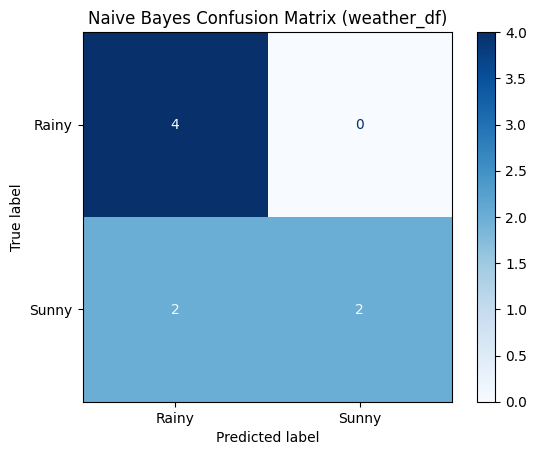

In [8]:
X = weather_df[["Humidity", "Temperature", "Wind Speed"]]
y = weather_df["Weather"]

# 2. Encode features
encoder = OrdinalEncoder()
X_encoded = encoder.fit_transform(X)

# 3. Fit Model (without alpha smoothing to match manual baseline frequencies)
model = CategoricalNB(alpha=1e-10)
model.fit(X_encoded, y)

# 4. Generate predictions across the training set
y_pred = model.predict(X_encoded)

# 5. Build raw text confusion matrix
cm = confusion_matrix(y, y_pred, labels=model.classes_)
print("Raw Confusion Matrix array layout:")
print(cm)

# 6. Render visual layout
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title("Naive Bayes Confusion Matrix (weather_df)")
plt.show()